# Clasificación de Sentimientos de Reseñas de Películas en IMDb con Redes Neuronales Recurrentes

*Maestría en Inteligencia Artificial - Técnicas de Deep Learning*

Los ratings y reseñas de películas son una fuente rica de datos textuales que pueden ser analizados para identificar el sentimiento subyacente, ya sea positivo o negativo. El uso de redes neuronales recurrentes (RNN) ha demostrado ser eficaz en la clasificación de secuencias de texto, ya que estas redes pueden capturar la información contextual en oraciones y palabras, identificando patrones relevantes para determinar la polaridad de una reseña.

## Redes Neuronales Recurrentes

Las RNN son especialmente adecuadas para el análisis de datos secuenciales como texto, ya que tienen la capacidad de almacenar y recordar información previa en la secuencia, lo cual es crucial para entender el contexto. Al aplicar una RNN a reseñas de películas, la red puede ser entrenada para identificar palabras, frases y patrones que generalmente se asocian con sentimientos positivos o negativos.

## Procesamiento de Texto

El procesamiento de texto para este proyecto implica convertir las reseñas en un formato numérico que la RNN pueda procesar. Esto se logra a través de técnicas como la tokenización y la vectorización de palabras (por ejemplo, utilizando embeddings). Luego, la RNN analizará la secuencia de palabras para clasificar cada reseña en una de dos categorías: positiva o negativa.

## Ventajas y Aplicaciones

Implementar RNN para la clasificación de sentimientos en reseñas de películas ofrece varias ventajas:

- **Detección precisa de emociones:** Mejora la capacidad de capturar sentimientos más matizados en textos largos y complejos.
- **Adaptabilidad a distintos idiomas y contextos:** Las RNN pueden ser entrenadas en diferentes conjuntos de datos para adaptarse a lenguajes y contextos específicos, como géneros de películas o plataformas de reseñas.
- **Asistencia en sistemas de recomendación:** Permite mejorar las recomendaciones personalizadas en plataformas de streaming basadas en el análisis de reseñas de usuarios.

## A. Objetivo

- Desarrollar un método basado en redes neuronales recurrentes que permita clasificar con precisión las reseñas de películas en IMDb en una de las dos categorías: positiva o negativa.

## B. Conjunto de datos

- Los datos corresponden a un dataset de reseñas de películas en IMDb, disponibles en el siguiente enlace. El dataset contiene miles de reseñas etiquetadas con su correspondiente rating y etiqueta de sentimiento (positivo o negativo).

## C. Actividades por realizar

1. **Preprocesamiento de las reseñas:** Construir un pipeline que permita limpiar y tokenizar las reseñas de texto, convirtiéndolas en secuencias numéricas utilizando embeddings (por ejemplo, Word2Vec o GloVe).
2. **Desarrollo de la arquitectura de red neuronal recurrente:** Implementar una RNN (por ejemplo, LSTM o GRU) para la clasificación de las reseñas en dos categorías. La arquitectura de la red es de libre elección, pero se sugiere incluir capas de embedding, capas recurrentes y una capa densa de salida con activación sigmoide. Justificar la elección de cada capa del modelo.
3. **Entrenamiento y evaluación del modelo:** Dividir el dataset en conjuntos de entrenamiento, validación y prueba. Entrenar el modelo utilizando el conjunto de entrenamiento y evaluar su rendimiento con el conjunto de prueba, reportando métricas de precisión, recall y F1-score.

In [ ]:
# !pip install torch gensim scikit-learn matplotlib seaborn pandas

In [4]:
import os, re, io, random, tarfile, copy, urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from gensim.models import Word2Vec
import truststore
truststore.inject_into_ssl()
import ssl, urllib.request

ctx = ssl.create_default_context()
ctx.load_default_certs()                      # certificados de Windows
ctx.verify_flags &= ~ssl.VERIFY_X509_STRICT   # quita la regla estricta de Python 3.13
urllib.request.install_opener(
    urllib.request.build_opener(urllib.request.HTTPSHandler(context=ctx))
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


## 1. Datos

Descargo el dataset y leo las reseñas de las carpetas `pos` y `neg` (train y test del original juntas, después hago mi propia partición).

In [5]:

base = "https://huggingface.co/datasets/stanfordnlp/imdb/resolve/main/plain_text/"
os.makedirs("data", exist_ok=True)

def cargar(nombre):
    ruta = f"data/{nombre}"
    if not os.path.exists(ruta):
        with urllib.request.urlopen(base + nombre, timeout=60) as r:
            datos = r.read()
        with open(ruta, "wb") as f:
            f.write(datos)
    return pd.read_parquet(ruta)

df = pd.concat([
    cargar("train-00000-of-00001.parquet"),
    cargar("test-00000-of-00001.parquet"),
]).rename(columns={"text": "review"})
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
print(df.shape)   # (50000, 2)
df.head()


(50000, 2)


,review,label
0,Forget what I said about Emeril. Rachael Ray i...,0
1,Former private eye-turned-security guard ditch...,0
2,Mann photographs the Alberta Rocky Mountains i...,0
3,Simply put: the movie is boring. Cliché upon c...,0
4,"Now being a fan of sci fi, the trailer for thi...",1


label
0    25000
1    25000
Name: count, dtype: int64
count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: n_palabras, dtype: float64


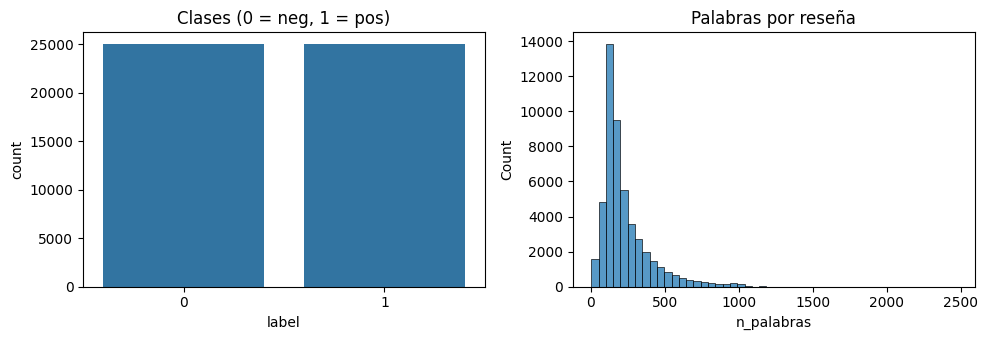

In [6]:
print(df["label"].value_counts())

df["n_palabras"] = df["review"].str.split().str.len()
print(df["n_palabras"].describe())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
sns.countplot(x="label", data=df, ax=ax[0])
ax[0].set_title("Clases (0 = neg, 1 = pos)")
sns.histplot(df["n_palabras"], bins=50, ax=ax[1])
ax[1].set_title("Palabras por reseña")
plt.tight_layout()
plt.show()

Las clases están balanceadas (25.000 y 25.000), así que accuracy sirve como métrica además de F1. La mayoría de reseñas tiene menos de 300 palabras, por eso voy a cortar las secuencias en 300.

## 2. Preprocesamiento

Limpieza: paso a minúsculas, quito el HTML (`<br />`), los links y los caracteres raros. Dejo los signos `!` y `?` porque pueden ayudar a detectar el sentimiento.

In [ ]:
def limpiar(texto):
    texto = texto.lower()
    texto = re.sub(r"<[^>]+>", " ", texto)
    texto = re.sub(r"http\S+|www\S+", " ", texto)
    texto = re.sub(r"[^a-z!?' ]+", " ", texto)
    texto = re.sub(r"([!?])", r" \1 ", texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto

df["tokens"] = df["review"].apply(limpiar).str.split()
print(df["review"][0][:250])
print(df["tokens"][0][:25])

In [ ]:
# 70% train, 15% validación, 15% prueba
train_df, resto = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(resto, test_size=0.50, stratify=resto["label"], random_state=SEED)
print(len(train_df), len(val_df), len(test_df))

El vocabulario y el Word2Vec los armo solo con el conjunto de entrenamiento, para no meter información de validación o prueba. Dejo 20.000 palabras; el índice 0 es el padding y el 1 las palabras desconocidas.

In [ ]:
MAX_VOCAB = 20000
MAX_LEN = 300
EMB_DIM = 100

contador = Counter(t for toks in train_df["tokens"] for t in toks)
palabras = [p for p, _ in contador.most_common(MAX_VOCAB - 2)]
word2idx = {p: i + 2 for i, p in enumerate(palabras)}

def codificar(tokens):
    ids = [word2idx.get(t, 1) for t in tokens][:MAX_LEN]
    # padding al inicio para que el último paso de la LSTM sea una palabra real
    return [0] * (MAX_LEN - len(ids)) + ids

def a_tensores(frame):
    X = torch.tensor([codificar(t) for t in frame["tokens"]])
    y = torch.tensor(frame["label"].values, dtype=torch.float32)
    return X, y

X_train, y_train = a_tensores(train_df)
X_val, y_val = a_tensores(val_df)
X_test, y_test = a_tensores(test_df)

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=256)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=256)
print(X_train.shape)

In [ ]:
w2v = Word2Vec(train_df["tokens"].tolist(), vector_size=EMB_DIM, window=5,
               min_count=2, sg=1, epochs=10, workers=4, seed=SEED)

print(w2v.wv.most_similar("great", topn=5))
print(w2v.wv.most_similar("terrible", topn=5))

# matriz de embeddings con el mismo orden que mi vocabulario
emb_matrix = np.zeros((MAX_VOCAB, EMB_DIM), dtype=np.float32)
for palabra, idx in word2idx.items():
    if palabra in w2v.wv:
        emb_matrix[idx] = w2v.wv[palabra]
emb_matrix[1] = np.random.normal(scale=0.1, size=EMB_DIM)

## 3. Modelo

Capas que usé y por qué:

- **Embedding** inicializado con los vectores de Word2Vec. Así la red parte con palabras que ya tienen significado y converge más rápido. Lo dejé entrenable para que se ajuste a la tarea.
- **Dropout** sobre los embeddings, para reducir el sobreajuste.
- **LSTM bidireccional**: la LSTM guarda información de palabras anteriores y evita el problema del gradiente que se desvanece. Bidireccional porque el sentido de una palabra puede depender de las que vienen después.
- **Dropout** a la salida de la LSTM, otra vez para regularizar.
- **Capa densa (64, ReLU)** que combina lo que extrajo la LSTM.
- **Capa de salida (1 neurona)**: la sigmoide la aplico dentro de la función de pérdida (`BCEWithLogitsLoss`) porque es más estable numéricamente, y a mano al predecir.

In [ ]:
class ModeloRNN(nn.Module):
    def __init__(self, emb_matrix, hidden=128):
        super().__init__()
        self.emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=0)
        self.drop_emb = nn.Dropout(0.3)
        self.lstm = nn.LSTM(emb_matrix.shape[1], hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(0.4)
        self.fc = nn.Linear(hidden * 2, 64)
        self.relu = nn.ReLU()
        self.out = nn.Linear(64, 1)

    def forward(self, x):
        x = self.drop_emb(self.emb(x))
        _, (h, _) = self.lstm(x)
        h = torch.cat([h[-2], h[-1]], dim=1)   # estado final de cada dirección
        h = self.drop(h)
        h = self.relu(self.fc(h))
        return self.out(h).squeeze(1)

modelo = ModeloRNN(emb_matrix).to(device)
print(modelo)

## 4. Entrenamiento

Uso Adam, y paro el entrenamiento si la pérdida de validación no mejora en 3 épocas, quedándome con los mejores pesos.

In [ ]:
criterio = nn.BCEWithLogitsLoss()
optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)

def una_epoca(loader, entrenar):
    modelo.train(entrenar)
    perdida, aciertos, total = 0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            salida = modelo(xb)
            loss = criterio(salida, yb)
            if entrenar:
                optimizador.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
                optimizador.step()
            perdida += loss.item() * len(yb)
            aciertos += ((salida > 0).float() == yb).sum().item()
            total += len(yb)
    return perdida / total, aciertos / total

historia = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}
mejor_loss, mejores_pesos, sin_mejora = float("inf"), None, 0

for epoca in range(1, 11):
    l, a = una_epoca(train_loader, True)
    vl, va = una_epoca(val_loader, False)
    historia["loss"].append(l); historia["val_loss"].append(vl)
    historia["acc"].append(a); historia["val_acc"].append(va)
    print(f"época {epoca}: loss {l:.4f} acc {a:.4f} | val_loss {vl:.4f} val_acc {va:.4f}")

    if vl < mejor_loss:
        mejor_loss = vl
        mejores_pesos = copy.deepcopy(modelo.state_dict())
        sin_mejora = 0
    else:
        sin_mejora += 1
        if sin_mejora == 3:
            print("paro el entrenamiento")
            break

modelo.load_state_dict(mejores_pesos)

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(historia["loss"], label="train")
ax[0].plot(historia["val_loss"], label="val")
ax[0].set_title("Pérdida")
ax[0].legend()
ax[1].plot(historia["acc"], label="train")
ax[1].plot(historia["val_acc"], label="val")
ax[1].set_title("Accuracy")
ax[1].legend()
plt.tight_layout()
plt.show()

## 5. Evaluación en el conjunto de prueba

In [ ]:
modelo.eval()
probs = []
with torch.no_grad():
    for xb, _ in test_loader:
        probs.append(torch.sigmoid(modelo(xb.to(device))).cpu())

probs = torch.cat(probs).numpy()
y_real = y_test.numpy().astype(int)
y_pred = (probs >= 0.5).astype(int)

print(classification_report(y_real, y_pred, target_names=["negativa", "positiva"], digits=4))

In [ ]:
cm = confusion_matrix(y_real, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["negativa", "positiva"], yticklabels=["negativa", "positiva"])
plt.xlabel("Predicho")
plt.ylabel("Real")
plt.show()

In [ ]:
# prueba con reseñas nuevas
def predecir(texto):
    ids = torch.tensor([codificar(limpiar(texto).split())]).to(device)
    with torch.no_grad():
        p = torch.sigmoid(modelo(ids)).item()
    return ("positiva" if p >= 0.5 else "negativa"), round(p, 3)

for r in ["An absolute masterpiece, the acting was brilliant and I loved every minute!",
          "Boring, predictable and way too long. A complete waste of time.",
          "Not bad, but I expected much more from the director."]:
    print(predecir(r), "-", r)

## 6. Conclusiones

(Completar con los resultados obtenidos al ejecutar el notebook: accuracy, precisión, recall y F1 en prueba, y si hubo sobreajuste según las curvas.)

Posibles mejoras: probar GloVe preentrenado, agregar atención, cambiar la longitud máxima de las secuencias o ajustar hiperparámetros.